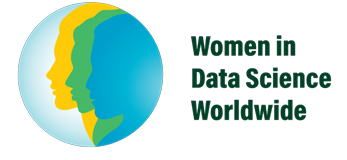

Name:Shashank Shetgeri Srn:02fe24bcs413
 
Name:Srushti Honnangi Srn:02fe23bcs062
 
Name:Anushri Kajagar  Srn:02fe23bcs084
 
Name: Tanvi Korgaonkar  Srn: 02fe23bcs013

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import os
import matplotlib.pyplot as plt

import sklearn
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, accuracy_score, confusion_matrix, roc_curve
from scipy.stats import zscore, pearsonr, uniform
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, StratifiedKFold, RandomizedSearchCV

from scipy.io import loadmat

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score

In [3]:
file_path_trainC = r"D:\WiDS\TRAIN_NEW\TRAIN_CATEGORICAL_METADATA_new.xlsx"
train_CATEGORICAL = pd.read_excel(file_path_trainC)
train_CATEGORICAL.head(10)

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,NaN,NaN
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,NaN,NaN
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,NaN,NaN
5,0cduHhwrQN4r,2017,1,0.0,0.0,2.0,18.0,25.0,15.0,40.0
6,0FUWCjn9YMN1,2017,1,0.0,1.0,2.0,15.0,0.0,15.0,30.0
7,0Hthz5IFXhpw,2016,2,0.0,1.0,1.0,12.0,35.0,18.0,40.0
8,0hzWGU6XYSVp,2019,3,0.0,0.0,3.0,21.0,45.0,21.0,45.0
9,0i2Tz2XUL4vm,2019,1,0.0,0.0,2.0,15.0,NaN,9.0,NaN


shows the content inside the file and the first 10 Rows from the file 

In [4]:
train_CATEGORICAL.columns

Index(['participant_id', 'Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
       'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
       'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
       'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
       'Barratt_Barratt_P2_Occ'],
      dtype='object')

shows the all the columns inside the file - train_categorical

In [5]:
file_path_trainFCM = (r"D:\WiDS\TRAIN_NEW\TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv")
train_FCM = pd.read_csv(file_path_trainFCM)
train_FCM.head()

,participant_id,0throw_1thcolumn,0throw_2thcolumn,0throw_3thcolumn,0throw_4thcolumn,0throw_5thcolumn,0throw_6thcolumn,0throw_7thcolumn,0throw_8thcolumn,0throw_9thcolumn,...,195throw_196thcolumn,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn
0,70z8Q2xdTXM3,0.222930,0.527903,0.429966,0.060457,0.566489,0.315342,0.508408,-0.078290,0.525692,...,0.224985,0.397448,0.422966,0.184642,0.305549,0.420349,0.016328,0.561864,0.471170,0.365221
1,WHWymJu6zNZi,0.614765,0.577255,0.496127,0.496606,0.404686,0.439724,0.122590,-0.085452,0.120673,...,0.217546,-0.014549,0.000440,-0.096451,0.454501,0.343916,0.167313,0.607656,0.550623,0.503176
2,4PAQp1M6EyAo,-0.116833,0.458408,0.260703,0.639031,0.769337,0.442528,0.637110,0.192010,0.520379,...,0.342487,-0.021141,-0.037836,0.075069,0.412712,0.292708,0.391005,0.461544,0.508912,0.624232
3,obEacy4Of68I,0.199688,0.752714,0.658283,0.575096,0.692867,0.645789,0.522750,0.412188,0.530843,...,0.103562,-0.178313,0.210983,-0.018666,0.436313,0.592982,0.216205,0.341272,0.440313,0.558193
4,s7WzzDcmDOhF,0.227321,0.613268,0.621447,0.562673,0.736709,0.589813,0.266676,0.359668,0.300771,...,-0.164956,0.007064,-0.120904,-0.488095,0.493575,-0.215361,0.210685,0.055850,0.119065,0.108273


In [6]:
train_FCM.columns

Index(['participant_id', '0throw_1thcolumn', '0throw_2thcolumn',
       '0throw_3thcolumn', '0throw_4thcolumn', '0throw_5thcolumn',
       '0throw_6thcolumn', '0throw_7thcolumn', '0throw_8thcolumn',
       '0throw_9thcolumn',
       ...
       '195throw_196thcolumn', '195throw_197thcolumn', '195throw_198thcolumn',
       '195throw_199thcolumn', '196throw_197thcolumn', '196throw_198thcolumn',
       '196throw_199thcolumn', '197throw_198thcolumn', '197throw_199thcolumn',
       '198throw_199thcolumn'],
      dtype='object', length=19901)

show all the columns inside the file TRAIN_FUNCTIONAL_CONNECTOME_MATRICES

In [7]:
file_path_trainQ = r"D:\WiDS\TRAIN_NEW\TRAIN_QUANTITATIVE_METADATA_new.xlsx"
train_QUANTITATIVE = pd.read_excel(file_path_trainQ)
train_QUANTITATIVE.head(10)

,participant_id,EHQ_EHQ_Total,ColorVision_CV_Score,APQ_P_APQ_P_CP,APQ_P_APQ_P_ID,APQ_P_APQ_P_INV,APQ_P_APQ_P_OPD,APQ_P_APQ_P_PM,APQ_P_APQ_P_PP,SDQ_SDQ_Conduct_Problems,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan
0,00aIpNTbG5uh,100.00,13.0,3.0,15.0,44.0,14.0,20.0,27.0,3.0,17.0,4.0,11.0,5.0,8.0,6.0,2.0,9.0,14.274127
1,00fV0OyyoLfw,92.27,14.0,3.0,12.0,35.0,25.0,28.0,30.0,5.0,20.0,4.0,13.0,5.0,8.0,7.0,3.0,8.0,NaN
2,04X1eiS79T4B,86.67,14.0,3.0,21.0,37.0,18.0,26.0,28.0,3.0,24.0,7.0,10.0,10.0,7.0,14.0,7.0,7.0,13.463381
3,05ocQutkURd6,93.34,14.0,3.0,11.0,42.0,15.0,20.0,28.0,0.0,5.0,0.0,3.0,0.0,3.0,2.0,2.0,6.0,9.572553
4,06YUNBA9ZRLq,0.00,14.0,8.0,12.0,35.0,22.0,12.0,24.0,6.0,23.0,7.0,15.0,8.0,9.0,8.0,1.0,4.0,6.654574
5,0cduHhwrQN4r,-100.00,14.0,5.0,16.0,36.0,19.0,13.0,22.0,6.0,22.0,1.0,16.0,5.0,10.0,6.0,5.0,6.0,NaN
6,0FUWCjn9YMN1,100.00,14.0,4.0,13.0,34.0,16.0,13.0,21.0,1.0,8.0,1.0,6.0,0.0,5.0,2.0,1.0,7.0,12.885580
7,0Hthz5IFXhpw,92.27,14.0,5.0,8.0,27.0,17.0,12.0,22.0,2.0,15.0,3.0,8.0,5.0,6.0,7.0,4.0,5.0,NaN
8,0hzWGU6XYSVp,73.34,14.0,3.0,17.0,42.0,18.0,19.0,22.0,2.0,18.0,6.0,5.0,4.0,3.0,13.0,7.0,6.0,12.486196
9,0i2Tz2XUL4vm,86.67,14.0,3.0,14.0,46.0,16.0,10.0,26.0,3.0,15.0,4.0,11.0,4.0,8.0,4.0,0.0,8.0,9.715491


shows the content inside the file -TRAIN_QUANTITATIVE_METADATA and the first 10 Rows from the file, 

In [8]:
train_QUANTITATIVE.columns

Index(['participant_id', 'EHQ_EHQ_Total', 'ColorVision_CV_Score',
       'APQ_P_APQ_P_CP', 'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV',
       'APQ_P_APQ_P_OPD', 'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP',
       'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Difficulties_Total',
       'SDQ_SDQ_Emotional_Problems', 'SDQ_SDQ_Externalizing',
       'SDQ_SDQ_Generating_Impact', 'SDQ_SDQ_Hyperactivity',
       'SDQ_SDQ_Internalizing', 'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial',
       'MRI_Track_Age_at_Scan'],
      dtype='object')

shows the all the columns inside the file - TRAIN_QUANTITATIVE_METADATA

In [9]:
file_path_trainS = r"D:\WiDS\TRAIN_NEW\TRAINING_SOLUTIONS.xlsx"
train_Solutions = pd.read_excel(file_path_trainS)
train_Solutions.head(10)

,participant_id,ADHD_Outcome,Sex_F
0,UmrK0vMLopoR,1,1
1,CPaeQkhcjg7d,1,0
2,Nb4EetVPm3gs,1,0
3,p4vPhVu91o4b,1,1
4,M09PXs7arQ5E,1,1
5,tBGXkEdv2cp7,1,0
6,DgRP31gu21O9,1,0
7,ClMA0FwvFgLY,1,0
8,NVUkahaJ6fhf,1,1
9,u0JiZgdGuYvh,1,0


shows the content inside the file -TRAINING_SOLUTIONS and the first 10 Rows from the file

In [10]:
train_Solutions.columns

Index(['participant_id', 'ADHD_Outcome', 'Sex_F'], dtype='object')

shows the all the columns inside the file -TRAINING_SOLUTIONS

In [11]:
train_CATEGORICAL.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213 entries, 0 to 1212
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   participant_id                    1213 non-null   object 
 1   Basic_Demos_Enroll_Year           1213 non-null   int64  
 2   Basic_Demos_Study_Site            1213 non-null   int64  
 3   PreInt_Demos_Fam_Child_Ethnicity  1170 non-null   float64
 4   PreInt_Demos_Fam_Child_Race       1159 non-null   float64
 5   MRI_Track_Scan_Location           1210 non-null   float64
 6   Barratt_Barratt_P1_Edu            1198 non-null   float64
 7   Barratt_Barratt_P1_Occ            1182 non-null   float64
 8   Barratt_Barratt_P2_Edu            1015 non-null   float64
 9   Barratt_Barratt_P2_Occ            991 non-null    float64
dtypes: float64(7), int64(2), object(1)
memory usage: 94.9+ KB


Gives all the inforamtion about the dataset "train_Categorical"  like the column name and if it contains the null value or not and there datatypes 

# Parent 1 level of education(Data Dictionary)

3=Less than 7th grade | 6=Junior high/Middle school (9th grade) | 9=Partial high school (10th or 11th grade) | 12=High school graduate | 15=Partial college (at least one year) | 18=College education | 21=Graduate degree

In [12]:
train_CATEGORICAL['Barratt_Barratt_P1_Edu'].value_counts()

Barratt_Barratt_P1_Edu
21.0    470
18.0    421
15.0    162
12.0     97
9.0      28
6.0      15
3.0       5
Name: count, dtype: int64

the above Distribution is of parent1's Education background 

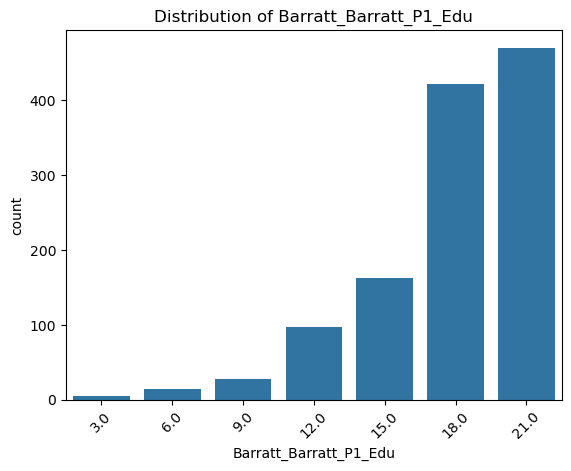

In [13]:
sns.countplot(x='Barratt_Barratt_P1_Edu', data=train_CATEGORICAL[['Barratt_Barratt_P1_Edu']])
plt.title(f"Distribution of Barratt_Barratt_P1_Edu")
plt.xticks(rotation=45)
plt.show()

graph show that 470 parents are having the job of 21=Graduate degree

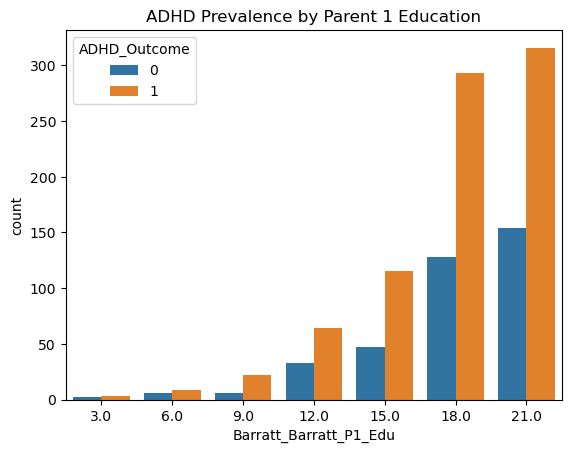

In [14]:
sns.countplot(data=train_CATEGORICAL, x='Barratt_Barratt_P1_Edu', hue=train_Solutions['ADHD_Outcome'])
plt.title('ADHD Prevalence by Parent 1 Education')
plt.show()

In the above graph we have ploted the parent1 education from the table with the train_CATEGORICAL dataset and comparing it with the dataset of train_Solutions which shows the ADHD outcomes , using the participant_id as a common ,we can see that the ADHD is found in the children whos parent1 Education is 21=Graduate degree , about 300+ tested people reported ADHD postive and around 150 people reported ADHD negative 

In [15]:
train_CATEGORICAL['Barratt_Barratt_P2_Edu'].value_counts()

Barratt_Barratt_P2_Edu
21.0    323
18.0    301
15.0    166
12.0    162
9.0      44
6.0      14
3.0       5
Name: count, dtype: int64

the above Distribution is of parent2's Education background

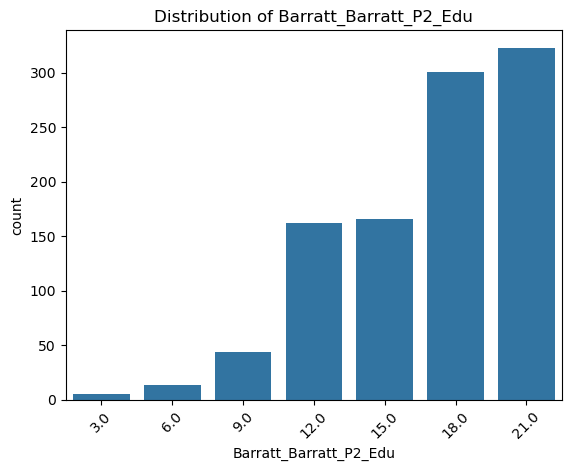

In [16]:
sns.countplot(x='Barratt_Barratt_P2_Edu', data=train_CATEGORICAL[['Barratt_Barratt_P2_Edu']])
plt.title(f"Distribution of Barratt_Barratt_P2_Edu")
plt.xticks(rotation=45)
plt.show()

it show that 323 parents 2 are having the job of 21=Graduate degree.

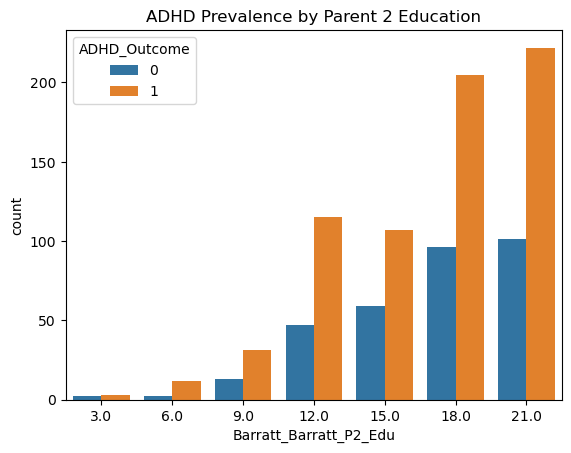

In [17]:
sns.countplot(data=train_CATEGORICAL, x='Barratt_Barratt_P2_Edu', hue=train_Solutions['ADHD_Outcome'])
plt.title('ADHD Prevalence by Parent 2 Education')
plt.show()

In the above graph we have ploted the parent1 education from the table with the train_CATEGORICAL dataset and comparing it with the dataset of train_Solutions which shows the ADHD outcomes , using the participant_id as a common ,we can see that the ADHD is found in the children whos parent2 Education is 21=Graduate degree , about 200+ tested people reported ADHD postive and around 110 people reported ADHD negative

# Parent 1 occupation(Data Dictionary)

0=Homemaker, stay at home parent.| 5=Day laborer, janitor, house cleaner, farm worker, food counter sales, food preparation worker, busboy.| 10=Garbage collector, short-order cook, cab driver, shoe sales, assembly line workers, masons, baggage porter.| 15=Painter, skilled construction trade, sales clerk, truck driver, cook, sales counter or general office clerk.| 20=Automobile mechanic, typist, locksmith, farmer, carpenter, receptionist, construction laborer, hairdresser.| 25=Machinist, musician, bookkeeper, secretary, insurance sales, cabinet maker, personnel specialist, welder.| 30=Supervisor, librarian, aircraft mechanic, artist and artisan, electrician, administrator, military enlisted personnel, buyer.| 35=Nurse, skilled technician, medical technician, counselor, manager, police and fire personnel, financial manager, physical, occupational, speech therapist.| 40=Mechanical, nuclear, and electrical engineer, educational administrator, veterinarian, military officer, elementary, high school and special education teacher.| 45=Physician, attorney, professor, chemical and aerospace engineer, judge, CEO, senior manager, public official, psychologist, pharmacist, accountant.|

In [18]:
train_CATEGORICAL['Barratt_Barratt_P1_Occ'].value_counts()

Barratt_Barratt_P1_Occ
0.0     286
35.0    219
45.0    187
30.0    154
40.0    154
25.0     79
15.0     35
5.0      31
20.0     31
10.0      6
Name: count, dtype: int64

the above Distribution is of parent1's occupation background

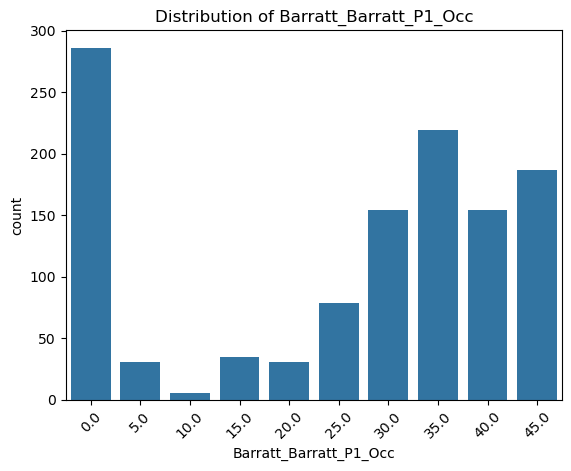

In [19]:
sns.countplot(x='Barratt_Barratt_P1_Occ', data=train_CATEGORICAL[['Barratt_Barratt_P1_Occ']])
plt.title(f"Distribution of Barratt_Barratt_P1_Occ")
plt.xticks(rotation=45)
plt.show()

graph show that 317 parents are having the job of 0=Homemaker, stay at home parent 

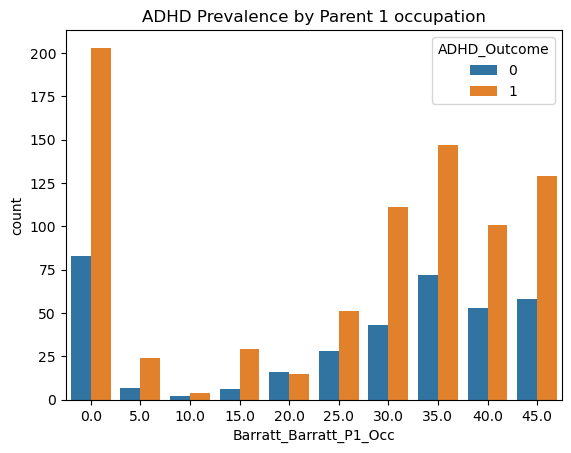

In [20]:
sns.countplot(data=train_CATEGORICAL, x='Barratt_Barratt_P1_Occ', hue=train_Solutions['ADHD_Outcome'])
plt.title('ADHD Prevalence by Parent 1 occupation')
plt.show()

In the above graph we have ploted the parent1 occupation from the table with the train_CATEGORICAL dataset and comparing it with the dataset of train_Solutions which shows the ADHD outcomes , using the participant_id as a common ,we can see that the ADHD is found in the children whos parent1 occupation is 0=Homemaker, stay at home parent. , about 210+ tested people reported ADHD postive and around 110 people reported ADHD negative

In [21]:
train_CATEGORICAL['Barratt_Barratt_P2_Occ'].value_counts()

Barratt_Barratt_P2_Occ
45.0    239
35.0    195
30.0    149
40.0    116
15.0     86
0.0      65
20.0     41
5.0      38
10.0     37
25.0     25
Name: count, dtype: int64

the above Distribution is of parent2's occupation background.

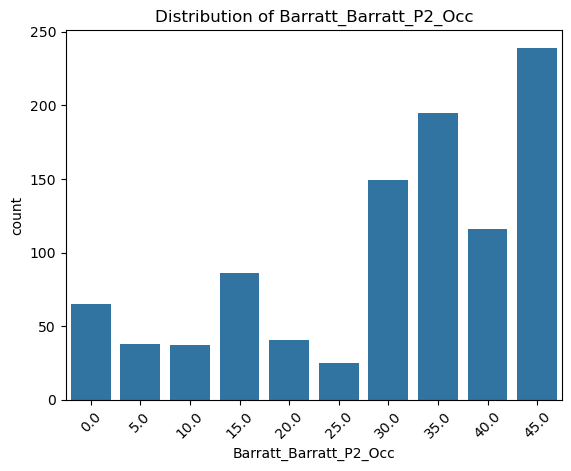

In [22]:
sns.countplot(x='Barratt_Barratt_P2_Occ', data=train_CATEGORICAL[['Barratt_Barratt_P2_Occ']])
plt.title(f"Distribution of Barratt_Barratt_P2_Occ")
plt.xticks(rotation=45)
plt.show()

Graph show that 287 parents are having the job of 0=Homemaker, stay at home parent.

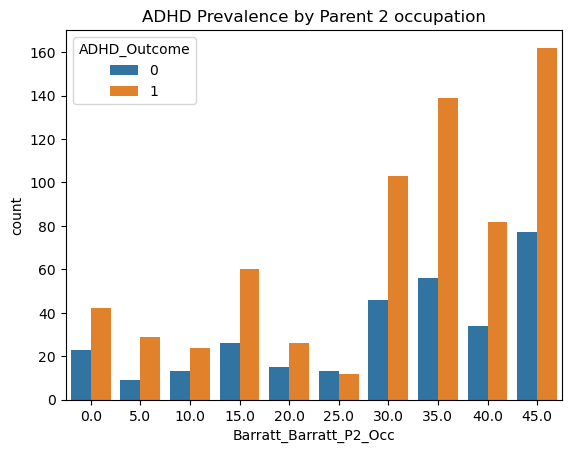

In [23]:
sns.countplot(data=train_CATEGORICAL, x='Barratt_Barratt_P2_Occ', hue=train_Solutions['ADHD_Outcome'])
plt.title('ADHD Prevalence by Parent 2 occupation')
plt.show()

In the above graph we have ploted the parent 2 occupation from the table with the train_CATEGORICAL dataset and comparing it with the dataset of train_Solutions which shows the ADHD outcomes , using the participant_id as a common ,we can see that the ADHD is found in the children whos parent1 occupation is 0=Homemaker, stay at home parent. , about 200 tested people reported ADHD postive and around 85 people reported ADHD negative

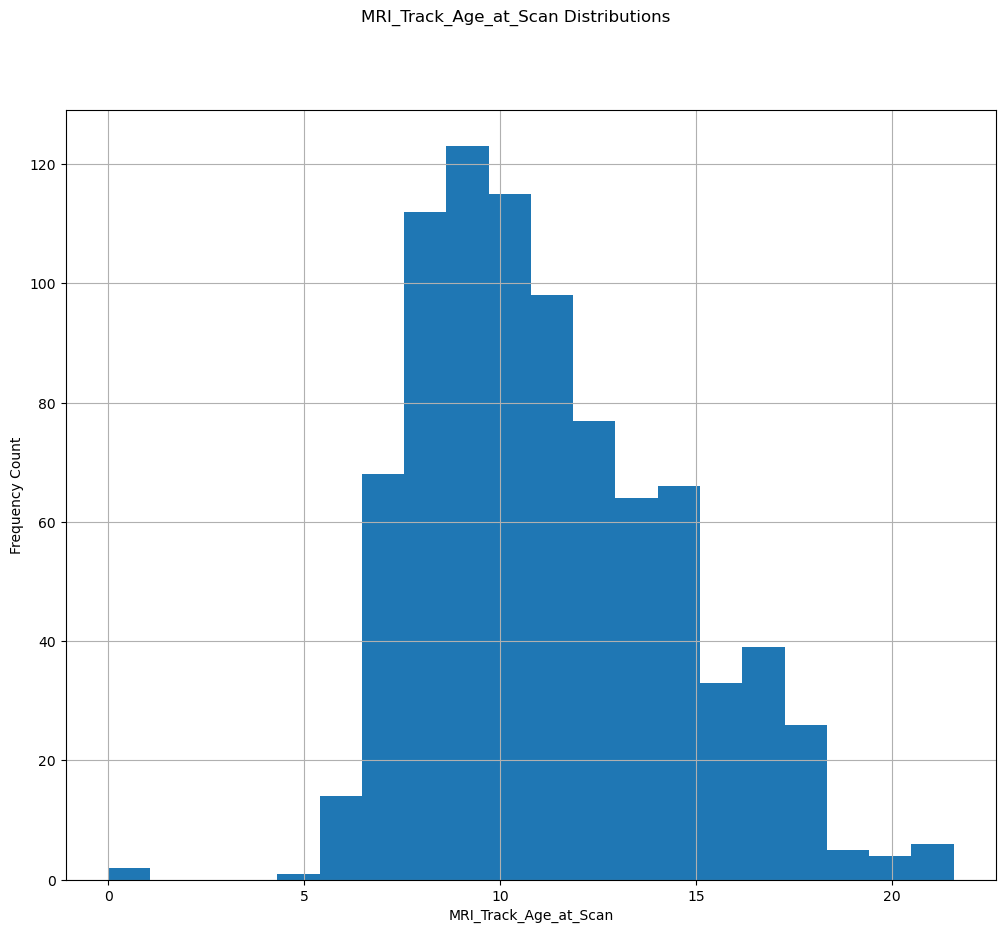

In [24]:
# Distribution of MRI_Track_Age_at_Scan
train_QUANTITATIVE['MRI_Track_Age_at_Scan'].hist(figsize=(12, 10), bins=20)
plt.suptitle("MRI_Track_Age_at_Scan Distributions")
plt.xlabel('MRI_Track_Age_at_Scan')
plt.ylabel('Frequency Count')
plt.show()

the above graph shows that the most MRI scan has be Done between the ages of 8 years to 10 years , based on the column = MRI_Track_Age_at_Scan , from the dataset of train_QUANTITATIVE

In [25]:
# ADHD distribution
train_Solutions['ADHD_Outcome'].value_counts()

ADHD_Outcome
1    831
0    382
Name: count, dtype: int64

show the Distribution of people having ADHD and the people not having ADHD

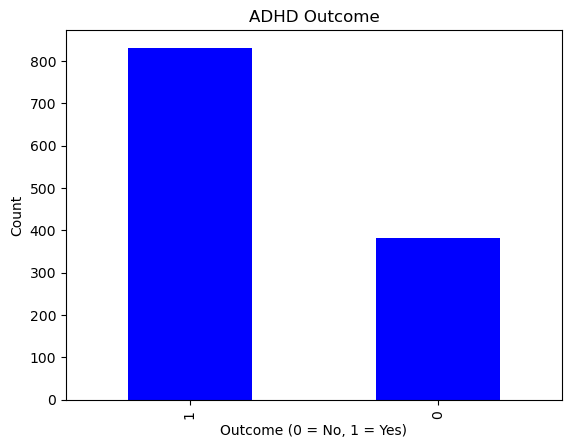

In [26]:
train_Solutions['ADHD_Outcome'].value_counts().plot(kind='bar', color='blue')
plt.title('ADHD Outcome')
plt.xlabel('Outcome (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

we can come to a conclusion that the people having ADHD have is Double than the people not having ADHD

In [27]:
# Gender distribution
train_Solutions['Sex_F'].value_counts()

Sex_F
0    797
1    416
Name: count, dtype: int64

show the Distribution of people having ADHD and the people not having ADHD based on Gender

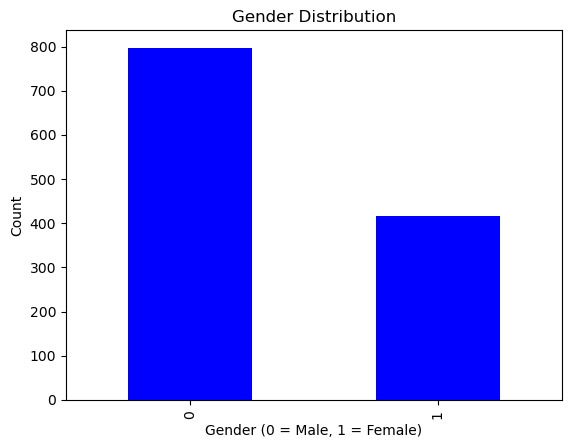

In [28]:
train_Solutions['Sex_F'].value_counts().plot(kind='bar', color='blue')
plt.title('Gender Distribution')
plt.xlabel('Gender (0 = Male, 1 = Female)')
plt.ylabel('Count')
plt.show()

Distribution shows that Male have twice the amount of ADHD that the women .

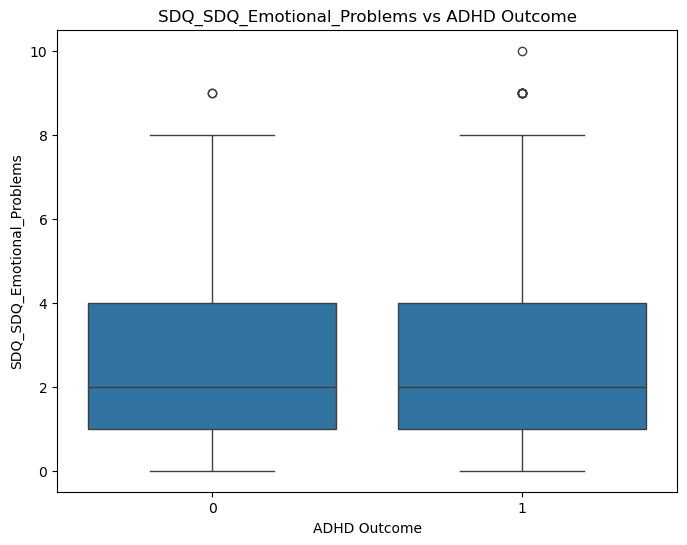

In [29]:

train_QUANTITATIVE_copy = train_QUANTITATIVE.copy()
train_QUANTITATIVE_copy['ADHD_Outcome'] = train_Solutions['ADHD_Outcome']

plt.figure(figsize=(8, 6))
sns.boxplot(x='ADHD_Outcome', y='SDQ_SDQ_Emotional_Problems', data=train_QUANTITATIVE_copy)
plt.title('SDQ_SDQ_Emotional_Problems vs ADHD Outcome')
plt.xlabel('ADHD Outcome')
plt.ylabel('SDQ_SDQ_Emotional_Problems')
plt.show()


certain Emotional_Problems can be used to Identifing the ADHD in people  

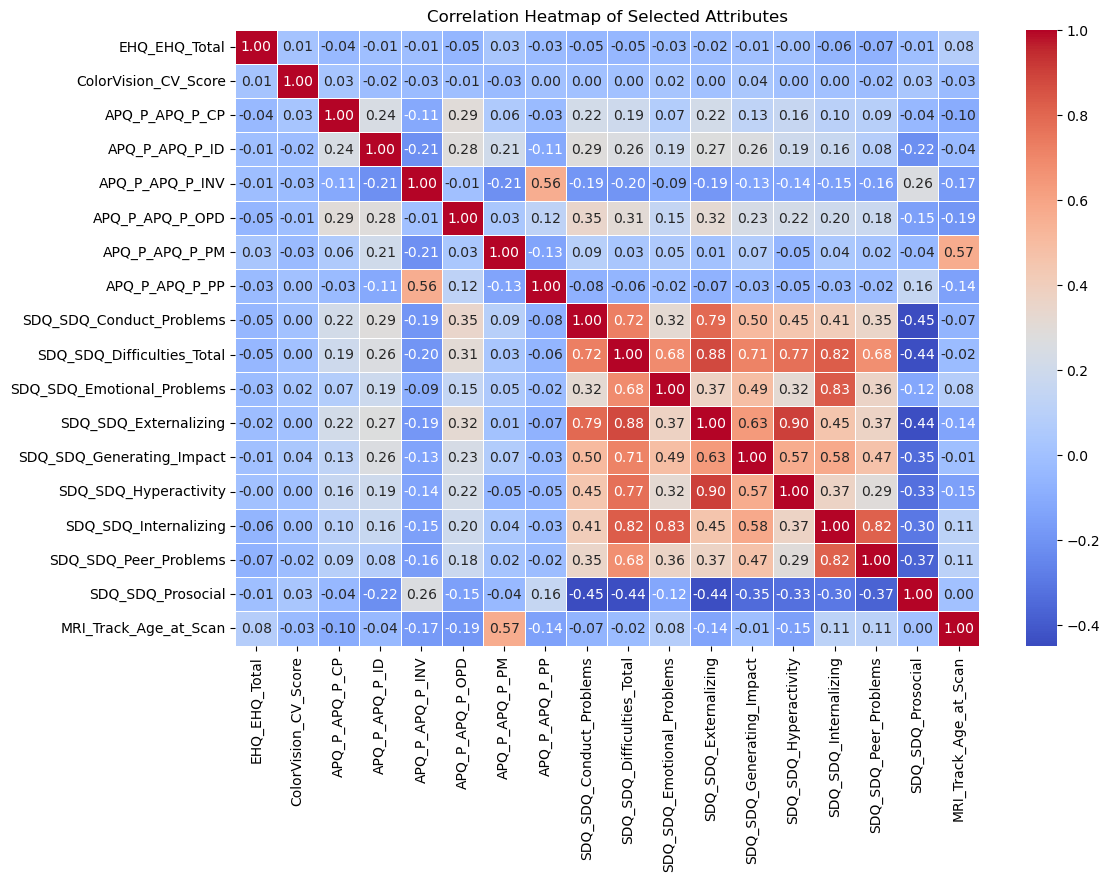

In [30]:
file_path = r"D:\WiDS\TRAIN_NEW\TRAIN_QUANTITATIVE_METADATA_new.xlsx"
df = pd.read_excel(file_path)
df_numeric = df.drop(columns=["participant_id"])

correlation_matrix = df_numeric.corr(method="pearson")
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Selected Attributes")
plt.show()
